# **Mental Health in Tech Survey - EDA**

##### **Project Type**    - EDA
##### **Contribution**    - Individual

# **Project Summary -**

This project explores the **OSMI (Open Sourcing Mental Illness) Mental Health in Tech Survey (2014)**, a dataset of 1,259 responses from employees in the tech industry, capturing their demographics, workplace policies, and attitudes toward mental health.

The goal of this EDA is to understand how frequently employees in tech seek treatment for mental health conditions, and how that relates to demographics (age, gender, country), workplace characteristics (company size, remote work, tech vs non-tech employer), and workplace mental-health support (benefits, care options, wellness programs, anonymity protections, ease of leave, and perceived consequences of disclosure).

**Data cleaning** was the first major challenge. The `Age` column contained clearly invalid entries (negative ages and absurdly large values such as `-1726` and `99999999999`), which were treated as missing and imputed with the median. The `Gender` column was free text with over 40 unique spellings (e.g. `M`, `m`, `Male`, `Cis Male`, `Malr`, `woman`, `Femake`, `queer`, `A little about you`) and was standardized into three buckets: `Male`, `Female`, and `Other/Non-binary`. Columns with very high missingness (`state`, which only applies to US respondents, and `comments`, a free-text field) were largely dropped or left as-is where irrelevant, while `self_employed` and `work_interfere` missing values were filled with sensible defaults (`No` and `Not applicable` respectively) based on the survey logic.

After cleaning, the notebook proceeds through a structured **Univariate → Bivariate → Multivariate (UBM)** visualization approach with more than 20 charts, covering: the distribution of age, gender, treatment-seeking, family history, and work interference; how treatment-seeking varies by gender, family history, company size, benefits, care options, anonymity, and ease of leave; and multivariate views combining gender, age, and family history together with treatment outcomes. A correlation heatmap (on label-encoded features) and a pairplot round out the relationship analysis.

**Key insights** include: employees with a family history of mental illness are far more likely to have sought treatment than those without; work interference is one of the strongest behavioral signals associated with treatment-seeking; awareness of care options and clarity around benefits correlate with higher treatment rates, while fear of negative consequences for disclosure correlates with lower willingness to discuss mental health with supervisors; and company size and remote-work status show weaker, but still noticeable, relationships with the availability of mental health benefits.

Overall, the analysis suggests that **transparency and communication of existing mental health resources** (rather than simply offering them) is what actually drives employees toward seeking help, and that reducing stigma around disclosure is likely to have a larger positive effect than adding new benefits alone. These findings are translated into concrete recommendations in the *Solution to Business Objective* section, aimed at HR and people-operations teams at tech companies who want to design more effective mental health support programs.

# **GitHub Link -**  

https://github.com/Manjula283/Mental-Health-Survey-EDA-Analysis

Provide your GitHub Link here.

# **Problem Statement**

Mental health remains a significantly under-discussed topic in tech workplaces, despite the high-pressure, high-stress nature of the industry. Employers often struggle to know whether the benefits and policies they offer (health coverage, wellness programs, anonymity guarantees, care-option awareness) actually translate into employees seeking treatment, and whether fear of stigma is undermining those efforts.

This project analyzes the 2014 OSMI Mental Health in Tech Survey to answer:
- What proportion of tech employees have sought treatment for a mental health condition, and how does this vary by demographic and workplace factors?
- Which workplace policies/attitudes (benefits, care options, anonymity, leave policy, fear of consequences) are most strongly associated with treatment-seeking behavior?
- Does company size, remote-work status, or employer type (tech vs. non-tech) meaningfully affect the availability of mental health support?
- Are there patterns that could help a company identify where its mental health support is falling short?

#### **Define Your Business Objective?**

The business objective is to help HR / People teams at tech companies **identify which workplace factors most strongly influence whether employees seek mental health treatment**, so they can prioritize investments (e.g., clearer communication of benefits, anonymity guarantees, manager training) that are most likely to increase treatment-seeking and reduce the stigma associated with disclosing mental health conditions at work.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Global plot styling
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'


### Dataset Loading

In [2]:
# Load Dataset
df = pd.read_csv('survey.csv')


### Dataset First View

In [3]:
# Dataset First Look
df.head()


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Number of Rows    : {df.shape[0]}")
print(f"Number of Columns : {df.shape[1]}")


Number of Rows    : 1259
Number of Columns : 27


### Dataset Information

In [5]:
# Dataset Info
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Timestamp                  1259 non-null   str  
 1   Age                        1259 non-null   int64
 2   Gender                     1259 non-null   str  
 3   Country                    1259 non-null   str  
 4   state                      744 non-null    str  
 5   self_employed              1241 non-null   str  
 6   family_history             1259 non-null   str  
 7   treatment                  1259 non-null   str  
 8   work_interfere             995 non-null    str  
 9   no_employees               1259 non-null   str  
 10  remote_work                1259 non-null   str  
 11  tech_company               1259 non-null   str  
 12  benefits                   1259 non-null   str  
 13  care_options               1259 non-null   str  
 14  wellness_program           1259 non

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")


Number of duplicate rows: 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
missing_df = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing_df / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'Missing Count': missing_df, 'Missing %': missing_pct})
missing_summary[missing_summary['Missing Count'] > 0]


,Missing Count,Missing %
comments,1095,86.97
state,515,40.91
work_interfere,264,20.97
self_employed,18,1.43


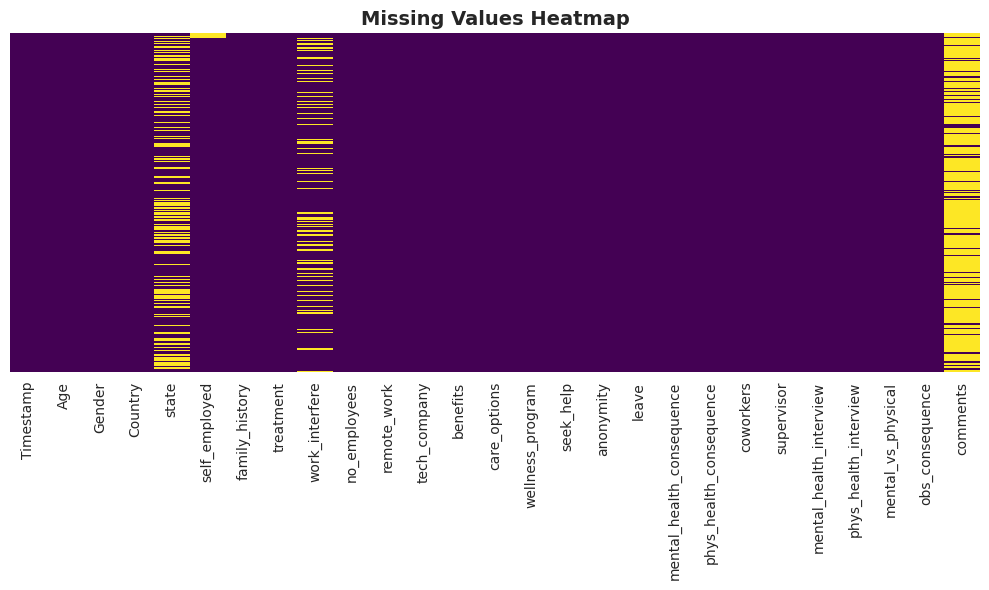

In [8]:
# Visualizing the missing values
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Heatmap')
plt.tight_layout()
plt.show()


The dataset has **1,259 rows and 27 columns**, mostly categorical (self-reported survey answers as free-form or fixed-choice text), with `Age` as the only true numeric column and `Timestamp` as a datetime string.

There are **no duplicate rows**. However, missingness is very uneven: `comments` (~87% missing) and `state` (~40% missing, since it only applies to respondents from the United States) have the most gaps. `work_interfere` (~21% missing) and `self_employed` (~1.4% missing) also have missing values, both of which are missing for a logical reason — `work_interfere` doesn't apply to people without a mental health condition, and `self_employed` was likely skipped by mistake or left blank when not applicable. All other columns are essentially complete. The `Age` and `Gender` columns also contain clear data-entry errors/inconsistencies that will need cleaning before analysis (handled in the Data Wrangling section).

## ***2. Understanding Variables***


In [9]:
# Dataset Columns
df.columns


Index(['Timestamp', 'Age', 'Gender', 'Country', 'state', 'self_employed',
       'family_history', 'treatment', 'work_interfere', 'no_employees',
       'remote_work', 'tech_company', 'benefits', 'care_options',
       'wellness_program', 'seek_help', 'anonymity', 'leave',
       'mental_health_consequence', 'phys_health_consequence', 'coworkers',
       'supervisor', 'mental_health_interview', 'phys_health_interview',
       'mental_vs_physical', 'obs_consequence', 'comments'],
      dtype='str')

In [10]:
# Dataset Describe
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Timestamp,1259,1246,2014-08-27 12:31:41,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1259.0,NaN,NaN,NaN,79428148.311358,2818299442.981968,-1726.0,27.0,31.0,36.0,99999999999.0
Gender,1259,49,Male,615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,1259,48,United States,751,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,744,45,CA,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
self_employed,1241,2,No,1095,NaN,NaN,NaN,NaN,NaN,NaN,NaN
family_history,1259,2,No,767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
treatment,1259,2,Yes,637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_interfere,995,4,Sometimes,465,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no_employees,1259,6,6-25,290,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

- **Timestamp** — date/time the survey was submitted.
- **Age** — respondent's age (contains invalid outliers to be cleaned).
- **Gender** — free-text gender (needs standardization).
- **Country / state** — respondent's location (state only for the US).
- **self_employed** — whether the respondent is self-employed.
- **family_history** — family history of mental illness (Yes/No).
- **treatment** — whether the respondent has sought treatment for a mental health condition (**our key outcome variable**).
- **work_interfere** — how much a mental health condition interferes with work.
- **no_employees** — company size bucket.
- **remote_work** — works remotely ≥50% of the time.
- **tech_company** — whether the employer is a tech company.
- **benefits, care_options, wellness_program, seek_help, anonymity, leave** — employer-provided mental health support and how easy it is to access.
- **mental_health_consequence, phys_health_consequence** — perceived negative consequences of disclosing a mental/physical health issue to the employer.
- **coworkers, supervisor** — willingness to discuss mental health with coworkers/supervisors.
- **mental_health_interview, phys_health_interview** — willingness to raise mental/physical health in a job interview.
- **mental_vs_physical** — whether the employer treats mental health as seriously as physical health.
- **obs_consequence** — whether the respondent has observed negative consequences for coworkers who disclosed a mental health condition.
- **comments** — free-text comments (mostly missing, not used in structured analysis).

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for column in df.columns:
    print(f"{column} -> {df[column].nunique()} unique values")


Timestamp -> 1246 unique values
Age -> 53 unique values
Gender -> 49 unique values
Country -> 48 unique values
state -> 45 unique values
self_employed -> 2 unique values
family_history -> 2 unique values
treatment -> 2 unique values
work_interfere -> 4 unique values
no_employees -> 6 unique values
remote_work -> 2 unique values
tech_company -> 2 unique values
benefits -> 3 unique values
care_options -> 3 unique values
wellness_program -> 3 unique values
seek_help -> 3 unique values
anonymity -> 3 unique values
leave -> 5 unique values
mental_health_consequence -> 3 unique values
phys_health_consequence -> 3 unique values
coworkers -> 3 unique values
supervisor -> 3 unique values
mental_health_interview -> 3 unique values
phys_health_interview -> 3 unique values
mental_vs_physical -> 3 unique values
obs_consequence -> 2 unique values
comments -> 160 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.

# 1) Work on a copy so the raw data stays untouched
df_clean = df.copy()

# 2) Convert Timestamp to datetime
df_clean['Timestamp'] = pd.to_datetime(df_clean['Timestamp'])

# 3) Clean Age: valid working-age range is roughly 15-75; anything outside is a data-entry error
df_clean.loc[(df_clean['Age'] < 15) | (df_clean['Age'] > 75), 'Age'] = np.nan
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
df_clean['Age'] = df_clean['Age'].astype(int)

# 4) Standardize Gender into 3 clean buckets: Male, Female, Other/Non-binary
def clean_gender(g):
    g = str(g).strip().lower()
    male_terms = ['male', 'm', 'man', 'cis male', 'cis man', 'malr', 'mal', 'maile',
                  'make', 'guy (-ish) ^_^', 'male-ish', 'male (cis)', 'msle', 'mail']
    female_terms = ['female', 'f', 'woman', 'cis female', 'femake', 'female (cis)',
                    'female (trans)', 'femail', 'cis-female/femme']
    if g in male_terms:
        return 'Male'
    elif g in female_terms:
        return 'Female'
    else:
        return 'Other/Non-binary'

df_clean['Gender'] = df_clean['Gender'].apply(clean_gender)

# 5) Handle missing values with logically appropriate defaults
df_clean['self_employed'] = df_clean['self_employed'].fillna('No')
df_clean['work_interfere'] = df_clean['work_interfere'].fillna('Not applicable')

# 6) Drop columns that are not useful for structured analysis (too sparse / free text / not needed)
df_clean.drop(columns=['comments', 'state', 'Timestamp'], inplace=True)

# 7) Quick sanity check
print("Shape after cleaning:", df_clean.shape)
print("\nRemaining missing values:\n", df_clean.isnull().sum().sum())
df_clean.head()


Shape after cleaning: (1259, 24)

Remaining missing values:
 0


,Age,Gender,Country,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,...,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence
0,37,Female,United States,No,No,Yes,Often,6-25,No,Yes,...,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No
1,44,Male,United States,No,No,No,Rarely,More than 1000,No,No,...,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No
2,32,Male,Canada,No,No,No,Rarely,6-25,No,Yes,...,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No
3,31,Male,United Kingdom,No,Yes,Yes,Often,26-100,No,Yes,...,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes
4,31,Male,United States,No,No,No,Never,100-500,Yes,Yes,...,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No


### What all manipulations have you done and insights you found?

**Manipulations performed:**
1. Parsed `Timestamp` to datetime, then dropped it (survey period doesn't affect this analysis).
2. Replaced invalid `Age` values (negative numbers, values like `-1726`, and absurd values like `99999999999`) with `NaN`, then imputed with the median age (~31), since only a handful of rows were affected.
3. Standardized `Gender` from 40+ free-text variants down to 3 categories: `Male`, `Female`, `Other/Non-binary` — this makes gender-based comparisons statistically meaningful instead of splitting the data into dozens of single-response buckets.
4. Filled `self_employed` missing values with `'No'` (the majority class) and `work_interfere` missing values with `'Not applicable'` (since this question is skipped by people without a mental health condition — the missingness itself is informative, not random).
5. Dropped `comments` (87% missing, free text) and `state` (only applicable to ~40% of respondents from the US) since they add more noise than signal to a structured EDA.

**Insights found:** After cleaning, gender skews heavily male (~79%), consistent with tech-industry demographics. The `work_interfere` missingness lines up almost exactly with respondents who reported no mental health condition, confirming the survey's skip logic. Age is fairly concentrated in the 25-40 range, typical of a tech workforce.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Age Distribution

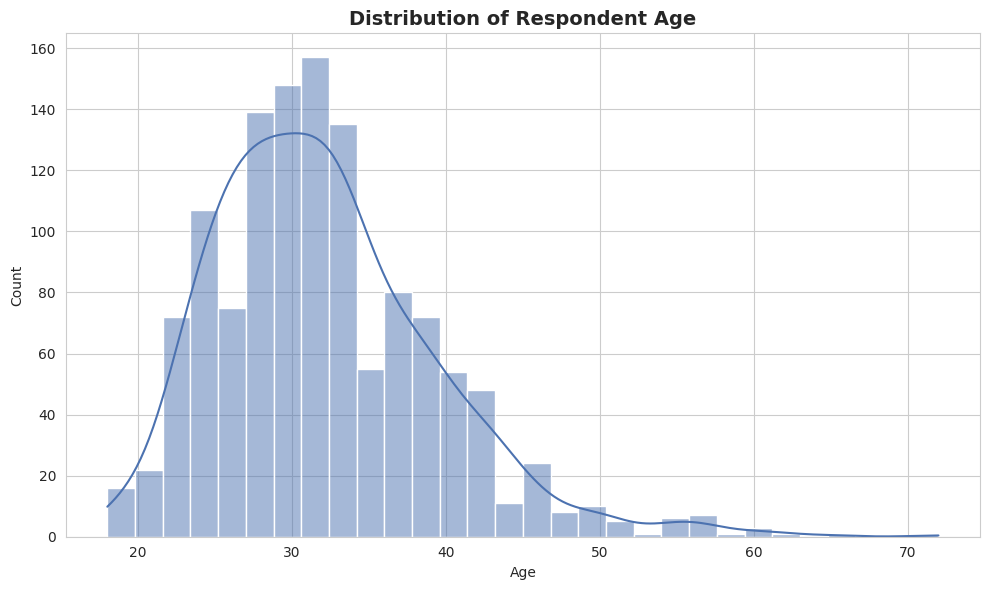

In [13]:
# Chart - 1 visualization code
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['Age'], bins=30, kde=True, color='#4C72B0')
plt.title('Distribution of Respondent Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A histogram with a KDE overlay is the standard choice for understanding the shape, center, and spread of a single continuous variable like Age.

##### 2. What is/are the insight(s) found from the chart?

The distribution is right-skewed and concentrated between 25-40 years, peaking around 28-32, consistent with a young tech workforce. After cleaning, there are no more unrealistic outliers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Understanding the age skew helps target mental-health programs (e.g., stress/burnout-specific programs for the dominant 25-35 age group) rather than a one-size-fits-all approach. No negative-growth insight here — it's purely descriptive.

#### Chart - 2 - Gender Distribution

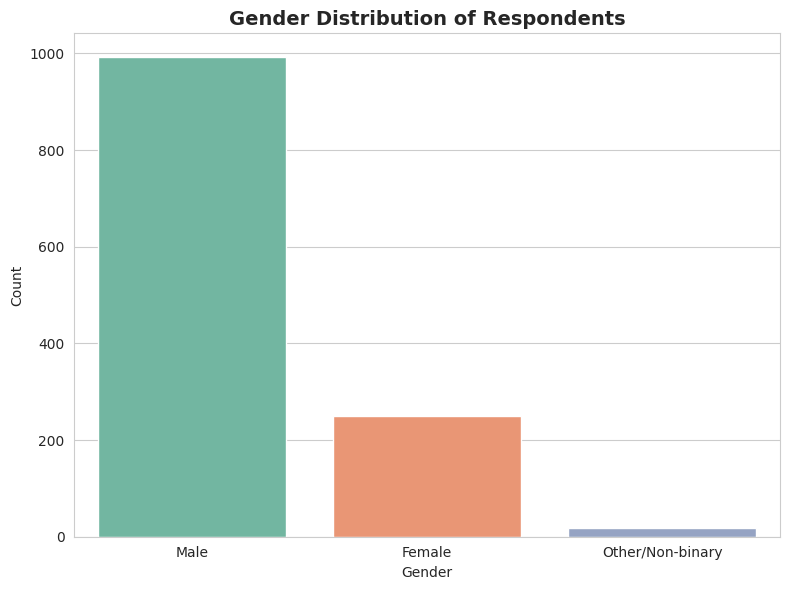

In [14]:
# Chart - 2 visualization code
plt.figure(figsize=(8, 6))
order = df_clean['Gender'].value_counts().index
sns.countplot(data=df_clean, x='Gender', order=order, palette='Set2')
plt.title('Gender Distribution of Respondents')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A count/bar plot is ideal for comparing frequencies across a small number of categories.

##### 2. What is/are the insight(s) found from the chart?

The sample is heavily male (~79%), followed by Female (~19%) and a small Other/Non-binary group (~2%), reflecting known gender imbalance in the tech industry.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This imbalance means any gender-based conclusions (especially for the Other/Non-binary group) should be treated with caution due to small sample size, even though the pattern itself (male-dominated tech workforce) is a well-established finding, not a new risk.

#### Chart - 3 - Treatment Sought Distribution

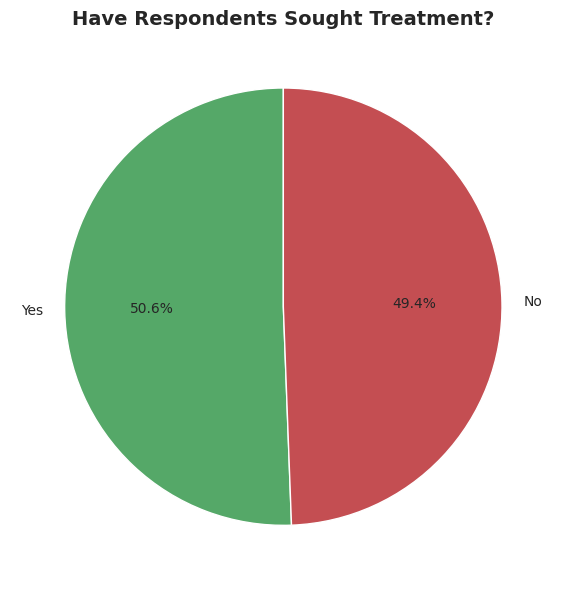

In [15]:
# Chart - 3 visualization code
plt.figure(figsize=(6, 6))
df_clean['treatment'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#55A868', '#C44E52'], startangle=90)
plt.title('Have Respondents Sought Treatment?')
plt.ylabel('')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A pie chart is effective for showing the proportion split of a binary outcome variable that will anchor the rest of the analysis.

##### 2. What is/are the insight(s) found from the chart?

Roughly half (50.6%) of respondents have sought treatment for a mental health condition, and half have not — an almost even split.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This near 50/50 split is a strong signal that treatment-seeking is not universal even when a condition may be present, reinforcing the business case for improving workplace support to shift more employees toward seeking help.

#### Chart - 4 - Family History Distribution

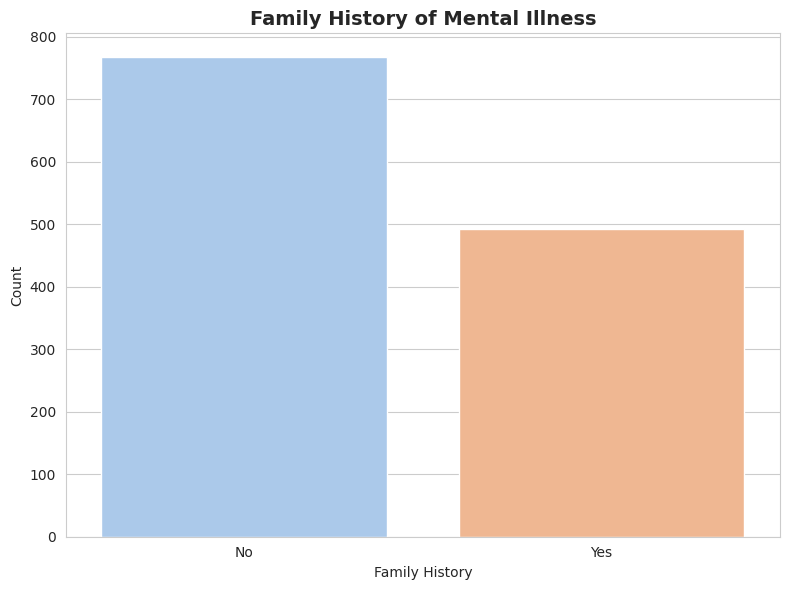

In [16]:
# Chart - 4 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='family_history', palette='pastel', order=df_clean['family_history'].value_counts().index)
plt.title('Family History of Mental Illness')
plt.xlabel('Family History')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A count plot clearly shows the split between respondents with and without a family history of mental illness.

##### 2. What is/are the insight(s) found from the chart?

About 39% of respondents report a family history of mental illness, while 61% do not — a substantial minority that is useful context for the later bivariate analysis against treatment.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

No direct negative-growth implication; this is a demographic baseline used to interpret later charts.

#### Chart - 5 - Work Interference Distribution

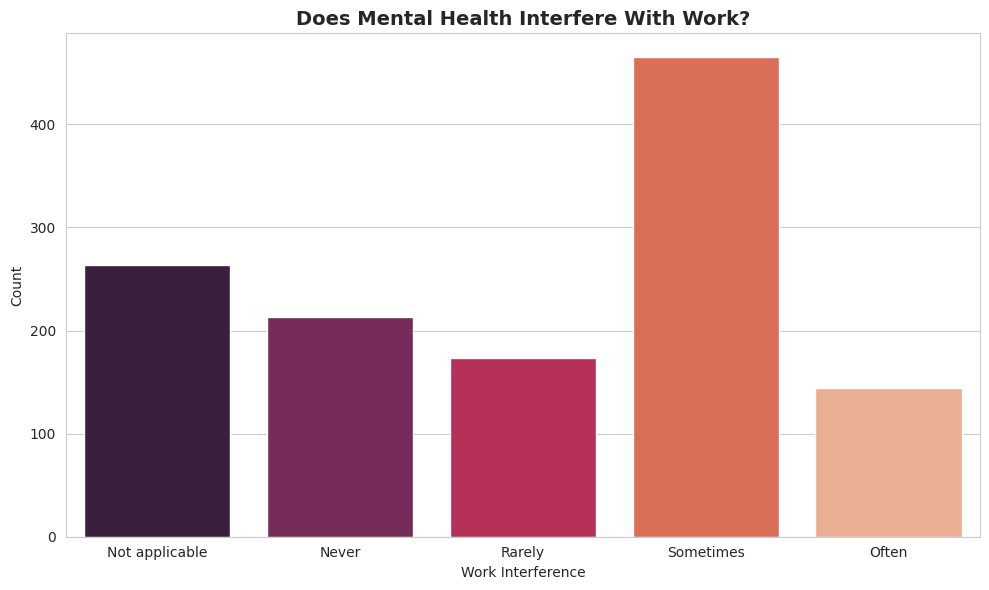

In [17]:
# Chart - 5 visualization code
plt.figure(figsize=(10, 6))
order = ['Not applicable', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df_clean, x='work_interfere', order=order, palette='rocket')
plt.title('Does Mental Health Interfere With Work?')
plt.xlabel('Work Interference')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

An ordered count plot preserves the natural ordinal scale of the responses (Never < Rarely < Sometimes < Often), making the trend easy to read.

##### 2. What is/are the insight(s) found from the chart?

Excluding 'Not applicable' (no condition), 'Sometimes' is the most common response, followed by 'Rarely', suggesting mental health conditions intermittently affect work for most affected employees rather than constantly.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Employers could use this to justify flexible/adaptive work policies (e.g., flexible hours on 'bad days') rather than blanket accommodations, since interference is often intermittent rather than constant.

#### Chart - 6 - Company Size Distribution

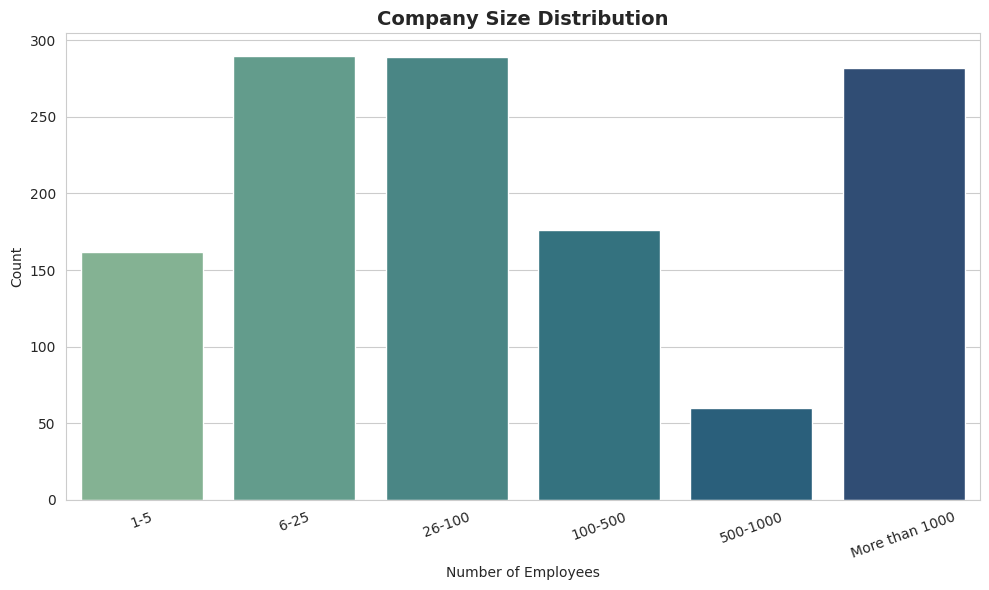

In [18]:
# Chart - 6 visualization code
plt.figure(figsize=(10, 6))
order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
sns.countplot(data=df_clean, x='no_employees', order=order, palette='crest')
plt.title('Company Size Distribution')
plt.xlabel('Number of Employees')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

An ordered categorical bar chart is appropriate to visualize the distribution of company-size buckets, which have a natural order.

##### 2. What is/are the insight(s) found from the chart?

Respondents are fairly evenly spread across company sizes, with a slight concentration in 'More than 1000' employees and '26-100', indicating the survey captured both large enterprises and small startups.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

A diverse company-size sample makes it easier to generalize benefit-availability findings later across small and large employers rather than being biased toward one segment.

#### Chart - 7 - Remote Work Distribution

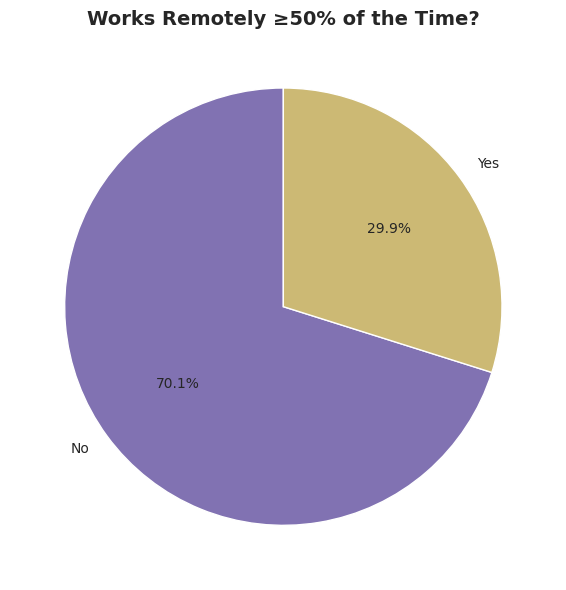

In [19]:
# Chart - 7 visualization code
plt.figure(figsize=(6, 6))
df_clean['remote_work'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#8172B2', '#CCB974'], startangle=90)
plt.title('Works Remotely ≥50% of the Time?')
plt.ylabel('')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A pie chart works well for this simple binary split.

##### 2. What is/are the insight(s) found from the chart?

Only about 30% of respondents work remotely at least half the time — in this 2014 dataset, in-office work was still the norm.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This is a useful baseline: any relationship found later between remote work and treatment-seeking should be interpreted knowing remote workers are a minority in this sample.

#### Chart - 8 - Top 10 Countries by Respondent Count

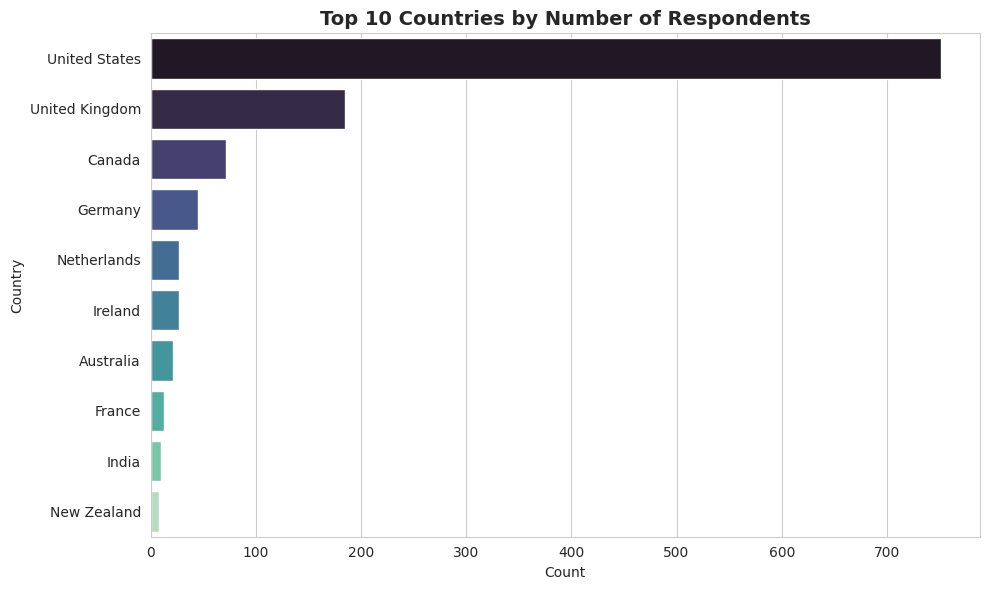

In [20]:
# Chart - 8 visualization code
plt.figure(figsize=(10, 6))
top_countries = df_clean['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='mako')
plt.title('Top 10 Countries by Number of Respondents')
plt.xlabel('Count')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart is best for ranking categories (countries) with long labels by frequency.

##### 2. What is/are the insight(s) found from the chart?

The United States dominates the sample (~60%), followed distantly by the United Kingdom and Canada, meaning the findings mostly reflect US workplace norms and healthcare context.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This is an important caveat: recommendations drawn from this dataset may not generalize well to countries with different healthcare systems (e.g., universal healthcare countries), and should be validated locally before being applied globally.

#### Chart - 9 - Mental Health Benefits Availability

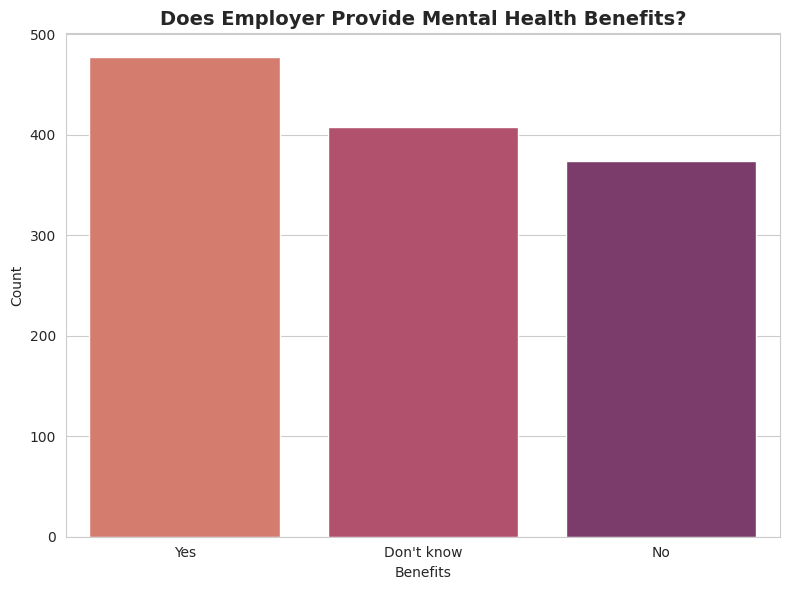

In [21]:
# Chart - 9 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='benefits', order=df_clean['benefits'].value_counts().index, palette='flare')
plt.title("Does Employer Provide Mental Health Benefits?")
plt.xlabel('Benefits')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A count plot clearly compares the three response categories (Yes/No/Don't know) for this key workplace-support variable.

##### 2. What is/are the insight(s) found from the chart?

Only about 39% of respondents confirm their employer provides mental health benefits, while a notable ~29% simply 'don't know' — almost as many as those who said 'No'.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The large 'Don't know' segment is itself a finding: it suggests a communication gap, not necessarily a lack of benefits. This is a low-cost, high-impact opportunity — improving internal communication about existing benefits could move some of that 29% into confirmed awareness without a policy change.

#### Chart - 10 - Age vs Treatment

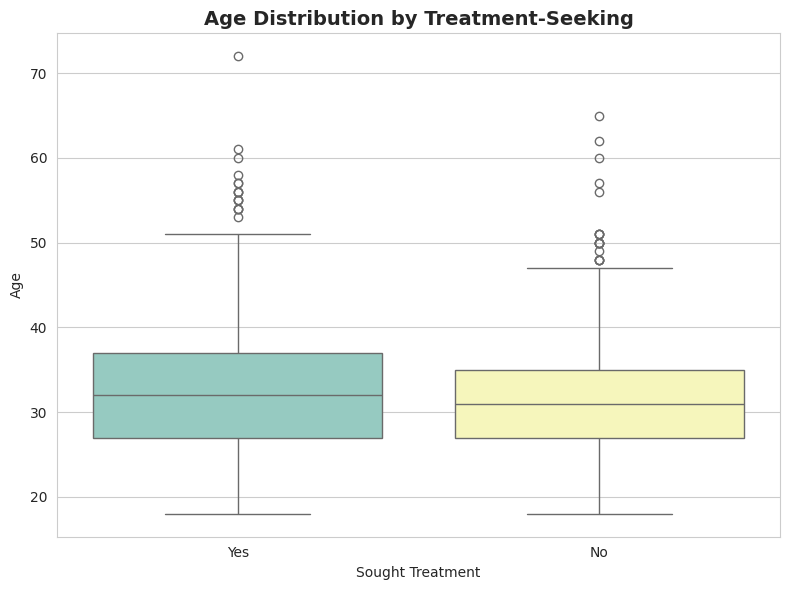

In [22]:
# Chart - 10 visualization code
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_clean, x='treatment', y='Age', palette='Set3')
plt.title('Age Distribution by Treatment-Seeking')
plt.xlabel('Sought Treatment')
plt.ylabel('Age')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A box plot is the standard way to compare the distribution of a numerical variable (Age) across two categorical groups (treatment Yes/No).

##### 2. What is/are the insight(s) found from the chart?

Median age is nearly identical between the two groups, with only a slightly higher median for those who sought treatment — age alone is not a strong differentiator of treatment-seeking behavior.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Since age is not a strong driver, mental-health outreach programs should not be age-targeted; broader, company-wide policies are more likely to be effective than age-specific initiatives.

#### Chart - 11 - Gender vs Treatment

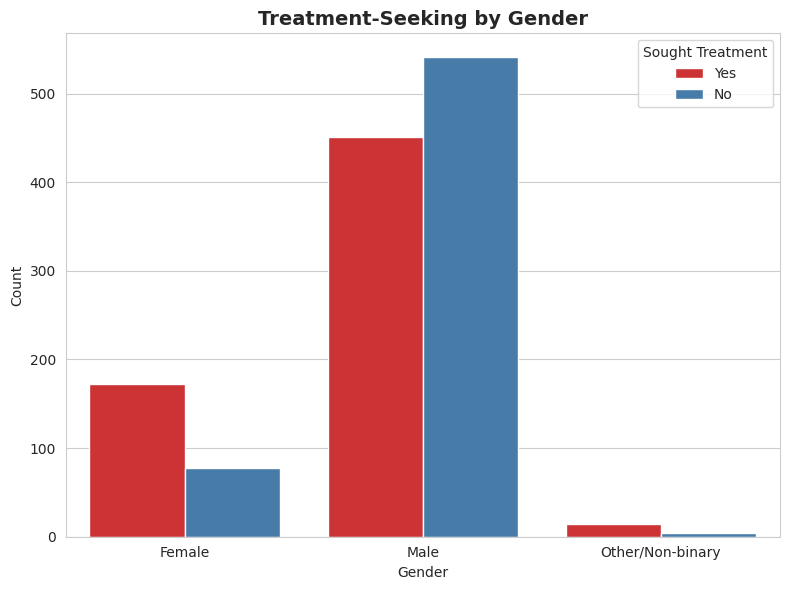

In [23]:
# Chart - 11 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='Gender', hue='treatment', palette='Set1')
plt.title('Treatment-Seeking by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A grouped count plot is well suited to compare a binary outcome (treatment) across categorical groups (gender).

##### 2. What is/are the insight(s) found from the chart?

Female and Other/Non-binary respondents seek treatment at a notably higher rate than Male respondents, where the split is closer to even.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This suggests outreach and stigma-reduction efforts may need to be especially targeted at male employees, who appear less likely to seek treatment relative to their peers — a potential negative-growth risk if untreated conditions among men go unaddressed and affect long-term productivity/retention.

#### Chart - 12 - Family History vs Treatment

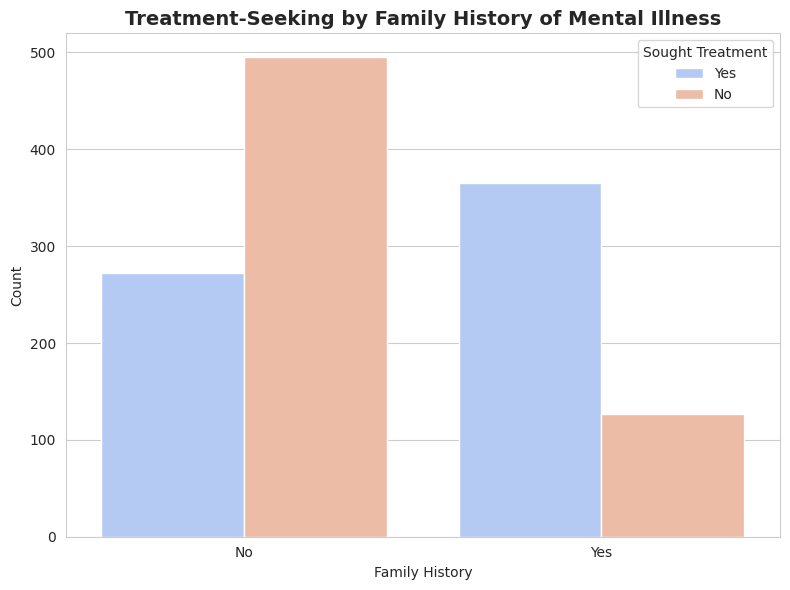

In [24]:
# Chart - 12 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='family_history', hue='treatment', palette='coolwarm')
plt.title('Treatment-Seeking by Family History of Mental Illness')
plt.xlabel('Family History')
plt.ylabel('Count')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A grouped count plot best highlights how treatment-seeking differs between two clear categories (family history Yes/No).

##### 2. What is/are the insight(s) found from the chart?

Respondents with a family history of mental illness are far more likely to have sought treatment (~75%) compared to those without (~35%) — one of the strongest relationships in the dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This is a strong positive insight: family history is a practical, low-friction signal that could be used in **opt-in** wellness screening/education programs, e.g., proactively offering information to employees who self-identify a family history, without being invasive.

#### Chart - 13 - Work Interference vs Treatment

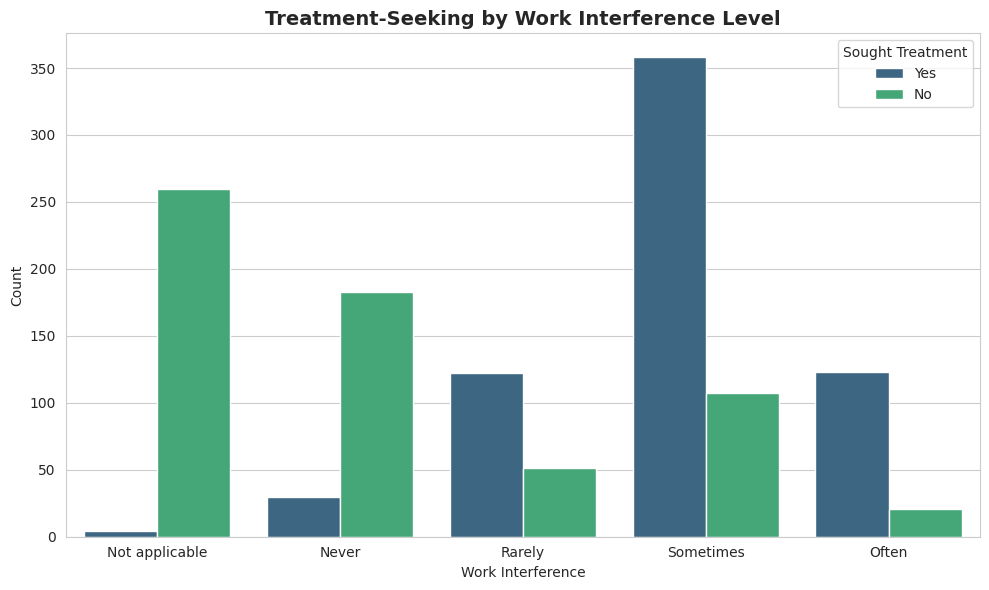

In [25]:
# Chart - 13 visualization code
plt.figure(figsize=(10, 6))
order = ['Not applicable', 'Never', 'Rarely', 'Sometimes', 'Often']
sns.countplot(data=df_clean, x='work_interfere', hue='treatment', order=order, palette='viridis')
plt.title('Treatment-Seeking by Work Interference Level')
plt.xlabel('Work Interference')
plt.ylabel('Count')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

An ordered grouped count plot shows how the treatment split changes as interference severity increases, respecting the ordinal nature of the variable.

##### 2. What is/are the insight(s) found from the chart?

Treatment-seeking rises sharply with interference severity — nearly all respondents reporting 'Often' interference have sought treatment, while very few reporting 'Never' have. This confirms work_interfere as the strongest behavioral predictor of treatment in the dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This is highly actionable: managers could be trained to recognize early, mild interference signals ('Rarely'/'Sometimes') and proactively point employees to resources, rather than waiting until interference becomes severe ('Often'), potentially reducing burnout-driven attrition.

#### Chart - 14 - Care Options Awareness vs Treatment

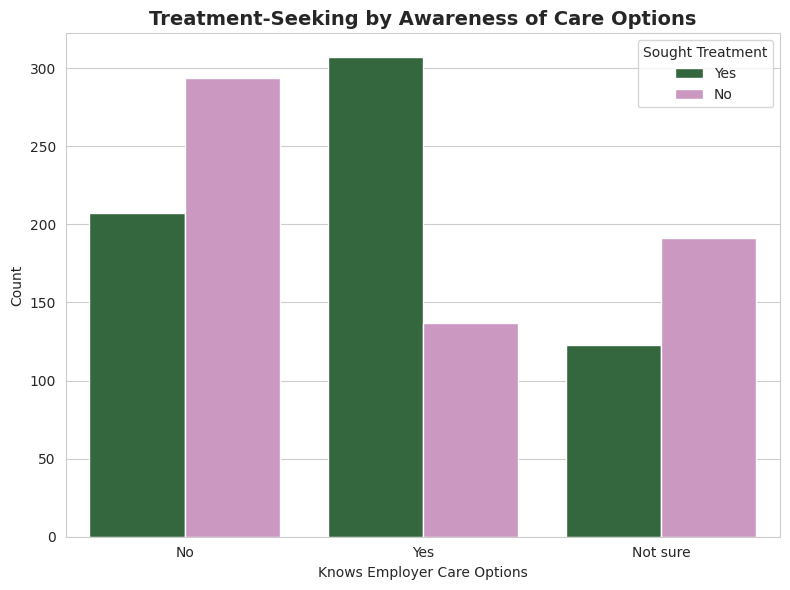

In [26]:
# Chart - 14 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='care_options', hue='treatment', order=df_clean['care_options'].value_counts().index, palette='cubehelix')
plt.title('Treatment-Seeking by Awareness of Care Options')
plt.xlabel('Knows Employer Care Options')
plt.ylabel('Count')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A grouped count plot compares treatment rates across the three awareness levels (Yes/No/Not sure).

##### 2. What is/are the insight(s) found from the chart?

Employees who know their employer's mental health care options seek treatment at a much higher rate (~65%) than those who say 'No' (~40%) or 'Not sure' (~35%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This directly supports investing in clearer communication of existing care options — a relatively low-cost intervention (e.g., onboarding materials, regular reminders) that appears strongly associated with more employees getting help.

#### Chart - 15 - Benefits vs Treatment

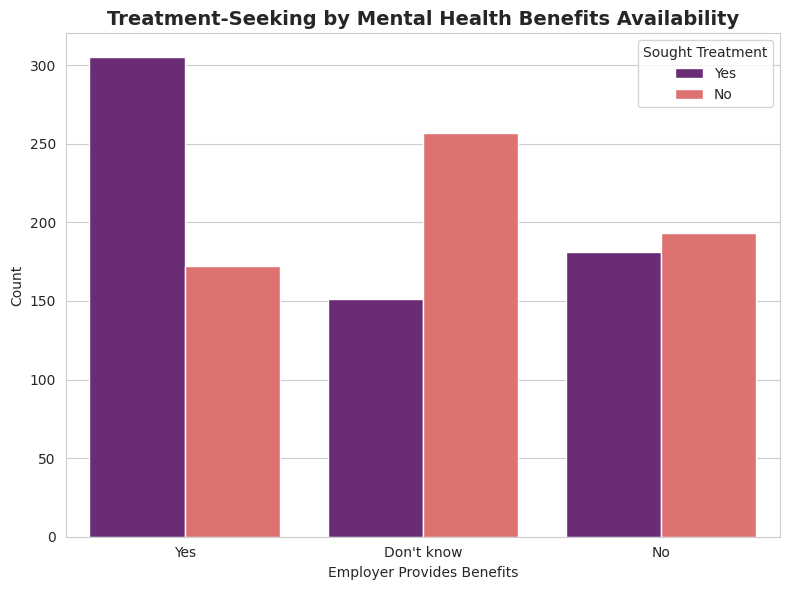

In [27]:
# Chart - 15 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='benefits', hue='treatment', order=df_clean['benefits'].value_counts().index, palette='magma')
plt.title('Treatment-Seeking by Mental Health Benefits Availability')
plt.xlabel('Employer Provides Benefits')
plt.ylabel('Count')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A grouped count plot lets us compare treatment-seeking rates across the benefits categories directly.

##### 2. What is/are the insight(s) found from the chart?

Respondents whose employer provides benefits seek treatment more often (~63%) than those who say 'No' (~45%) or 'Don't know' (~44%) — confirming that formal benefits do correlate with treatment, though the gap is smaller than for care-option awareness.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: expanding benefits access could help, but the smaller gap (vs. care_options) suggests that simply offering benefits without ensuring employees know about and understand them yields diminishing returns — awareness may matter more than the benefit itself.

#### Chart - 16 - Anonymity Protection vs Treatment

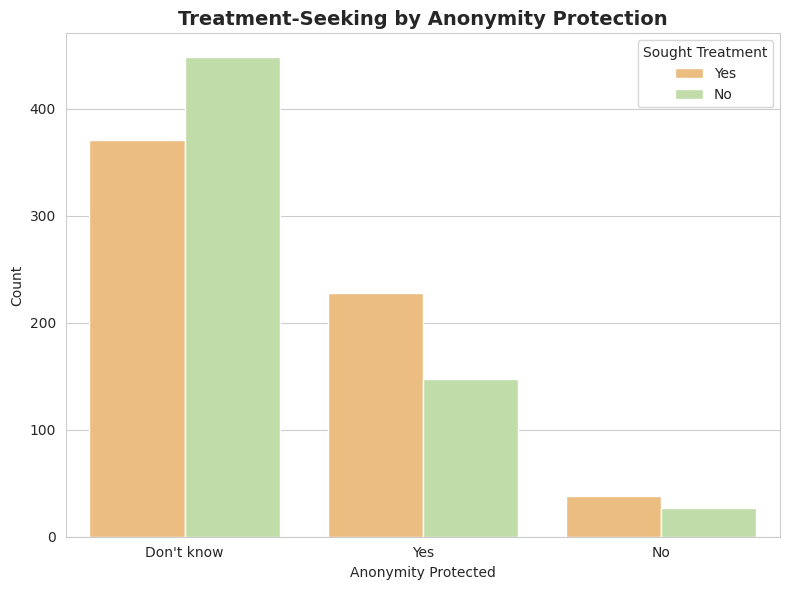

In [28]:
# Chart - 16 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='anonymity', hue='treatment', order=df_clean['anonymity'].value_counts().index, palette='Spectral')
plt.title('Treatment-Seeking by Anonymity Protection')
plt.xlabel('Anonymity Protected')
plt.ylabel('Count')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A grouped count plot highlights whether perceived confidentiality protections relate to treatment-seeking behavior.

##### 2. What is/are the insight(s) found from the chart?

The 'Yes' group has a noticeably higher treatment rate than the large 'Don't know' group, which is the majority response — most employees are simply unsure whether their anonymity is protected.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The dominance of 'Don't know' responses (rather than 'No') again points to a communication gap rather than a policy gap — clearly and repeatedly communicating anonymity guarantees could be a quick win to boost treatment-seeking confidence.

#### Chart - 17 - Ease of Leave vs Fear of Mental Health Consequences

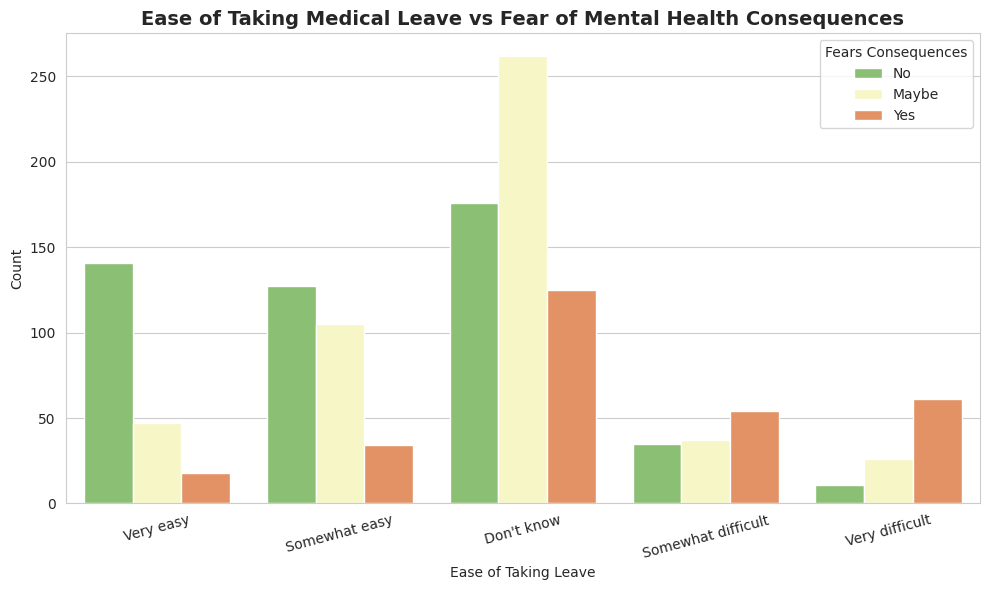

In [29]:
# Chart - 17 visualization code
plt.figure(figsize=(10, 6))
leave_order = ['Very easy', 'Somewhat easy', "Don't know", 'Somewhat difficult', 'Very difficult']
sns.countplot(data=df_clean, x='leave', hue='mental_health_consequence', order=leave_order, palette='RdYlGn_r')
plt.title('Ease of Taking Medical Leave vs Fear of Mental Health Consequences')
plt.xlabel('Ease of Taking Leave')
plt.ylabel('Count')
plt.xticks(rotation=15)
plt.legend(title='Fears Consequences')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

An ordered grouped count plot shows how perceived leave difficulty relates to fear of negative consequences from disclosure, both being ordinal/categorical.

##### 2. What is/are the insight(s) found from the chart?

Respondents who find leave 'Very difficult' or 'Somewhat difficult' report fearing consequences far more often than those who find it 'Very easy' — and a large 'Don't know' group again dominates the leave-ease question.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This links two policy levers together: making leave policies clear and genuinely easy to use appears associated with less fear of stigma. Ambiguous leave policies (the large 'Don't know' segment) may be silently discouraging people from taking needed time off — a potential negative-growth risk if unaddressed (burnout, presenteeism).

#### Chart - 18 - Company Size vs Benefits Availability

<Figure size 1200x600 with 0 Axes>

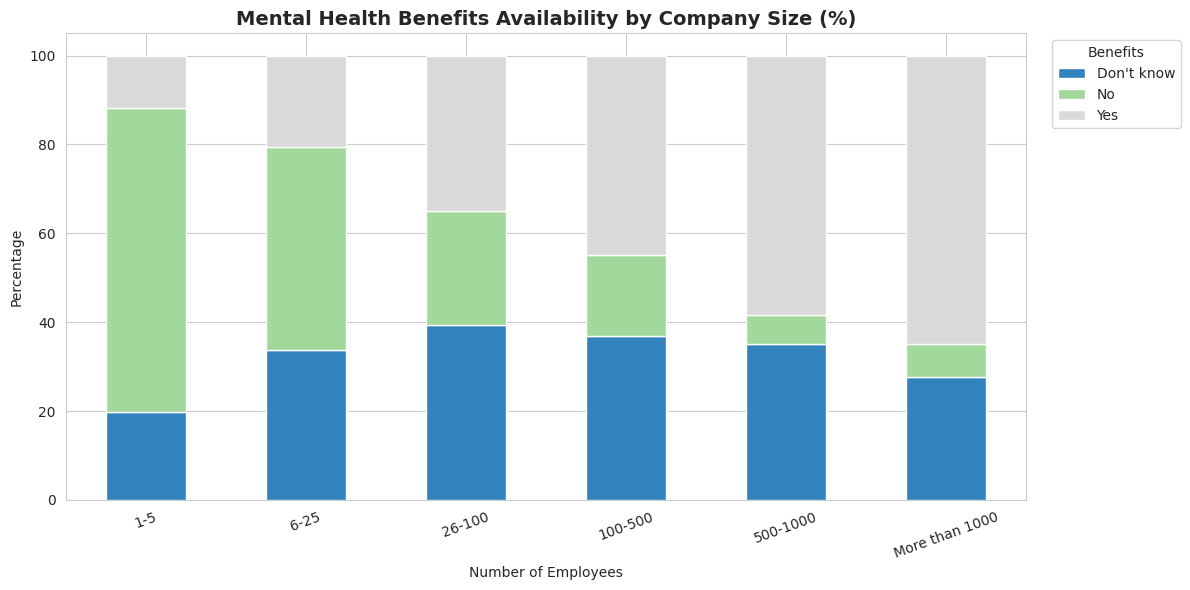

In [30]:
# Chart - 18 visualization code
plt.figure(figsize=(12, 6))
order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
ct = pd.crosstab(df_clean['no_employees'], df_clean['benefits'], normalize='index').reindex(order) * 100
ct.plot(kind='bar', stacked=True, colormap='tab20c', figsize=(12, 6))
plt.title('Mental Health Benefits Availability by Company Size (%)')
plt.xlabel('Number of Employees')
plt.ylabel('Percentage')
plt.xticks(rotation=20)
plt.legend(title='Benefits', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A 100%-stacked bar chart is ideal for comparing the proportional composition of a categorical variable (benefits) across an ordered categorical variable (company size).

##### 2. What is/are the insight(s) found from the chart?

Larger companies (500+ employees) are far more likely to formally provide mental health benefits, while small companies (1-5, 6-25 employees) show much higher 'No' and 'Don't know' shares.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This is an important equity insight: employees at small/early-stage companies are structurally disadvantaged in mental health support. For a business audience, this means startups may need to consider low-cost alternatives (EAPs, stipends) since traditional benefit packages scale with company size.

#### Chart - 19 - Remote Work vs Treatment

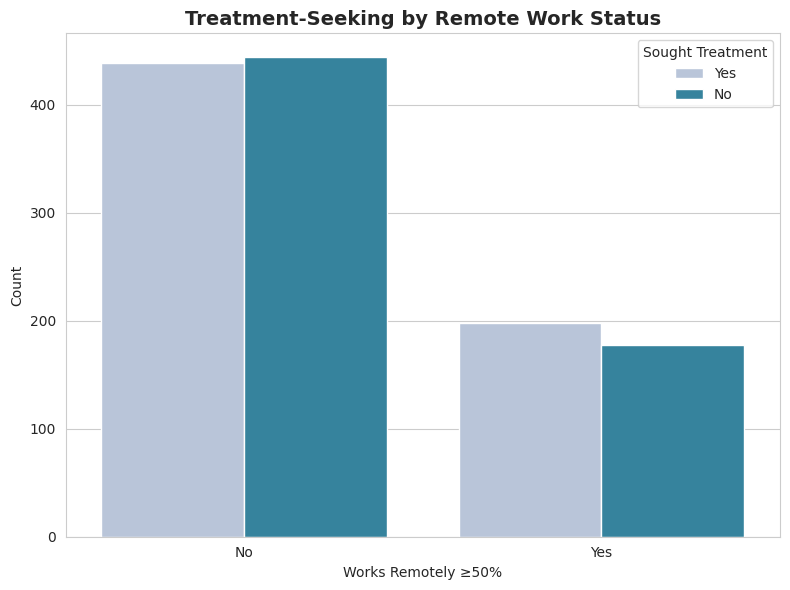

In [31]:
# Chart - 19 visualization code
plt.figure(figsize=(8, 6))
sns.countplot(data=df_clean, x='remote_work', hue='treatment', palette='PuBuGn')
plt.title('Treatment-Seeking by Remote Work Status')
plt.xlabel('Works Remotely ≥50%')
plt.ylabel('Count')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A grouped count plot is appropriate for comparing a binary outcome across a binary predictor.

##### 2. What is/are the insight(s) found from the chart?

Treatment-seeking rates are almost identical between remote and non-remote workers, indicating remote work status alone doesn't meaningfully influence treatment-seeking in this sample.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

No strong actionable signal here — this suggests companies shouldn't assume that remote-work policy changes alone will affect mental-health treatment rates; other factors (stigma, awareness) matter more.

#### Chart - 20 - Gender, Family History & Treatment (Multivariate)

<Figure size 1000x600 with 0 Axes>

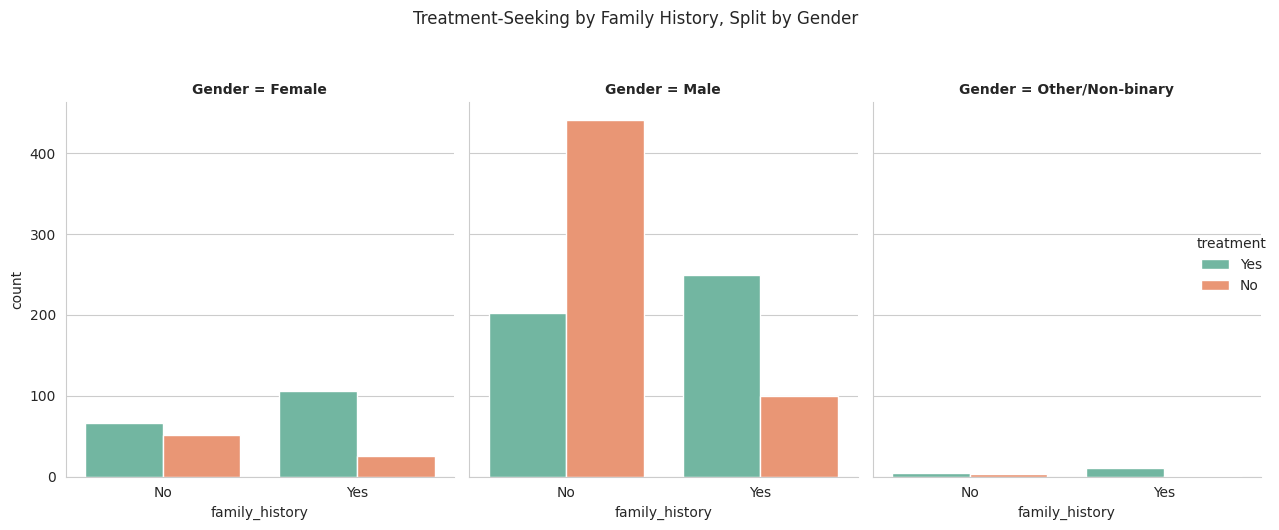

In [32]:
# Chart - 20 visualization code
plt.figure(figsize=(10, 6))
g = sns.catplot(data=df_clean, x='family_history', hue='treatment', col='Gender',
                 kind='count', palette='Set2', height=5, aspect=0.8)
g.fig.suptitle('Treatment-Seeking by Family History, Split by Gender', y=1.05)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A faceted count plot (catplot with `col`) lets us examine the relationship between two categorical variables (family history and treatment) separately within each gender group — a genuine multivariate view.

##### 2. What is/are the insight(s) found from the chart?

The strong 'family history → treatment' relationship holds within every gender group, but the gap between 'has family history' and 'no family history' is widest for Male respondents, suggesting family history has an especially strong influence on whether men seek treatment.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This refines the earlier gender insight: outreach to male employees could be specifically framed around family-history awareness (e.g., 'if mental illness runs in your family, here's what support is available'), which may resonate more than generic messaging.

#### Chart - 21 - Age Distribution by Gender, Split by Treatment (Multivariate)

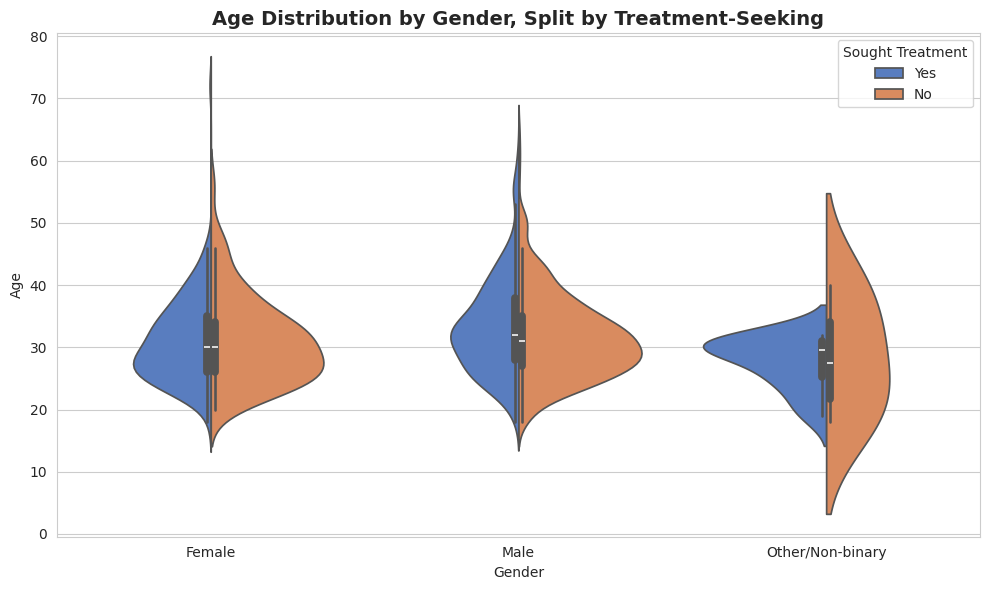

In [33]:
# Chart - 21 visualization code
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_clean, x='Gender', y='Age', hue='treatment', split=True, palette='muted')
plt.title('Age Distribution by Gender, Split by Treatment-Seeking')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.legend(title='Sought Treatment')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A split violin plot packs three dimensions (age distribution, gender, and treatment) into a single readable chart, showing both distribution shape and group comparison at once.

##### 2. What is/are the insight(s) found from the chart?

Age distributions are broadly similar across gender and treatment groups, reinforcing that age is not a major differentiator, while gender-based differences (seen in Chart 11) hold across the age range rather than being concentrated in a specific age band.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms that interventions should be designed around gender/awareness factors rather than age segments, consistent with the age-related insight from Chart 10.

#### Chart - 22 - Correlation Heatmap

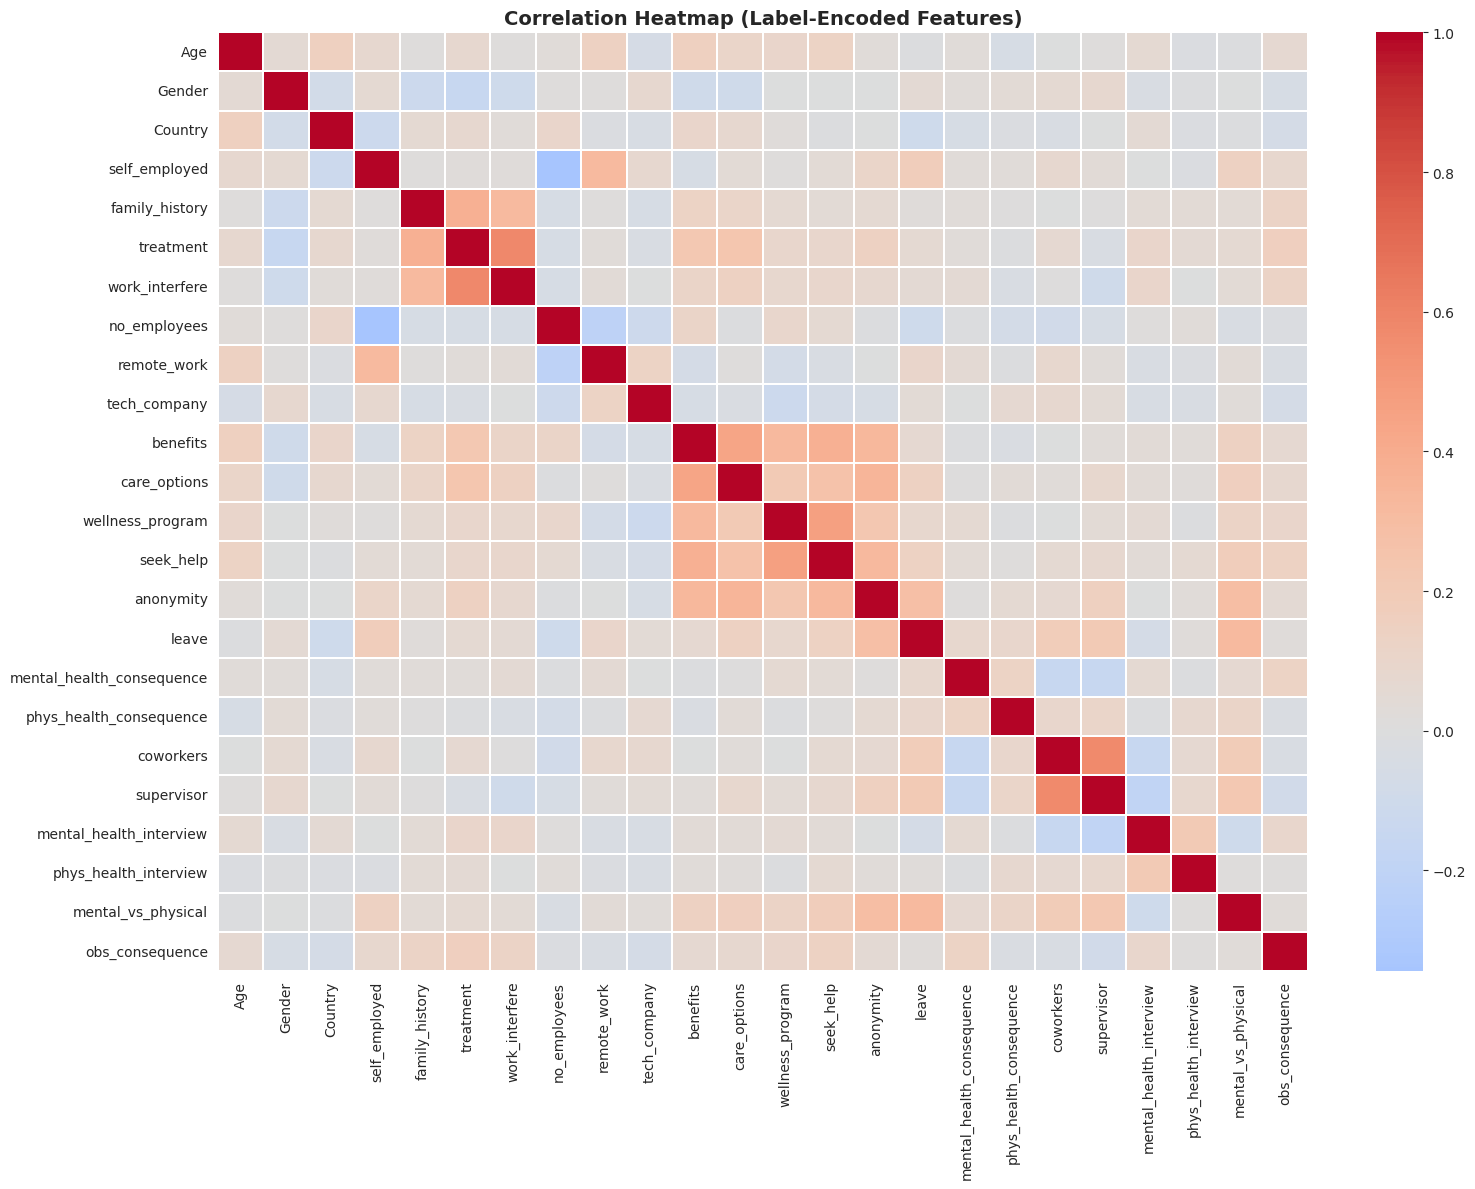

In [34]:
# Correlation Heatmap visualization code
from sklearn.preprocessing import LabelEncoder

df_encoded = df_clean.copy()
le = LabelEncoder()
for col in df_encoded.select_dtypes(include='object').columns:
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))

plt.figure(figsize=(16, 12))
corr = df_encoded.corr()
sns.heatmap(corr, cmap='coolwarm', annot=False, center=0, linewidths=0.3)
plt.title('Correlation Heatmap (Label-Encoded Features)')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A heatmap is the standard way to visualize pairwise correlation across many encoded variables at once, helping spot the strongest linear relationships.

##### 2. What is/are the insight(s) found from the chart?

`treatment` shows its strongest correlations with `family_history`, `work_interfere`, and `care_options`, consistent with the bivariate findings above. Most other workplace-policy variables show weak-to-moderate correlations with each other (e.g., `benefits`, `wellness_program`, `seek_help` cluster together), suggesting companies that offer one form of support tend to offer several.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This validates that `family_history`, `work_interfere`, and `care_options` are the top three factors to prioritize when designing interventions — a data-driven way to focus limited HR resources rather than spreading efforts thin across all 20+ policy variables.

#### Chart - 23 - Pair Plot

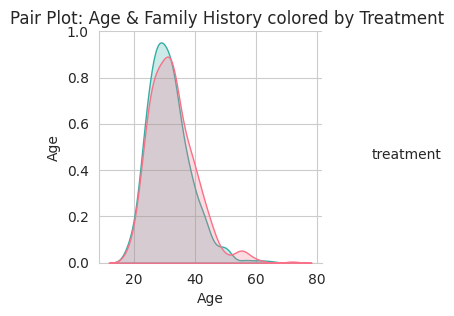

In [35]:
# Pair Plot visualization code
pairplot_df = df_clean[['Age', 'family_history', 'treatment']].copy()
sns.pairplot(pairplot_df, hue='treatment', palette='husl', diag_kind='kde', height=3)
plt.suptitle('Pair Plot: Age & Family History colored by Treatment', y=1.02)
plt.show()


##### 1. Why did you pick the specific chart?

A pair plot is useful to check the numeric variable (Age) for any interaction effects with treatment and family history in a single combined view, even though the dataset is mostly categorical.

##### 2. What is/are the insight(s) found from the chart?

There's no strong visual separation by age alone (confirming Chart 10/21), and the KDE diagonal shows treatment-seeking respondents are spread across the same age range as non-seekers — age simply doesn't segment the outcome well in this dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Reinforces (rather than reveals new) findings: with only one true numeric variable, deeper multivariate structure lives in the categorical variables (family_history, work_interfere, care_options) rather than in Age.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

Based on the analysis, the following actions are recommended for tech-company HR/People teams to increase mental-health treatment-seeking among employees:

1. **Prioritize communication over new policy creation.** A large share of respondents answered 'Don't know' to benefits, anonymity, and care-option questions — not 'No'. This is the single biggest, lowest-cost opportunity: run regular, clear communication campaigns (onboarding, intranet, manager reminders) about existing mental health resources.
2. **Train managers to recognize early work-interference signals.** Since treatment-seeking rises sharply with interference severity, coaching managers to notice early signs ('Rarely'/'Sometimes' interference) and proactively point employees to resources can intervene before conditions become severe.
3. **Make care-option and benefit information genuinely easy to find**, since awareness of care options showed one of the strongest positive relationships with treatment-seeking — stronger than the mere existence of benefits.
4. **Address the gender gap directly** with messaging that acknowledges men are statistically less likely to seek treatment, and consider anonymous/no-stigma channels first, since male respondents showed the lowest treatment rate.
5. **Support small companies differently.** Since benefit availability scales with company size, small companies/startups should be encouraged to adopt low-cost alternatives (Employee Assistance Programs, mental-health stipends, telehealth partnerships) rather than full in-house benefit packages.
6. **Simplify and clarify medical leave policy for mental health**, since unclear/difficult leave policies correlate with higher fear of negative consequences from disclosure.

**Any insight that could lead to negative growth?** The dataset is heavily skewed toward the US (~60%) and male respondents (~79%), so recommendations should be validated against the specific company's own demographic and country mix before being applied — over-generalizing US-centric findings to teams in countries with different healthcare/labor norms could lead to ineffective or even counterproductive policies.

# **Conclusion**

This EDA of the 2014 OSMI Mental Health in Tech Survey shows that whether a tech employee seeks treatment for a mental health condition is driven far more by **awareness and communication of workplace support** (care options, benefits clarity, anonymity assurances) and by **personal/behavioral signals** (family history, degree of work interference) than by demographic factors like age or remote-work status. Gender does show a meaningful gap, with male respondents seeking treatment less often than female and non-binary respondents.

The data cleaning step (standardizing `Gender`, correcting invalid `Age` values, and handling missingness in `work_interfere`/`self_employed` based on survey skip-logic) was essential to make fair, reliable comparisons. The UBM (Univariate → Bivariate → Multivariate) visualization approach, backed by a correlation heatmap and pair plot, consistently pointed to the same three variables — `family_history`, `work_interfere`, and `care_options` — as the strongest correlates of treatment-seeking, giving HR teams a clear, data-driven starting point for where to focus mental-health support investments.